# Online Shopping Behaviour Analysis
Statistical and mathematical techniques on the UCI *Online Shoppers Purchasing Intention* dataset (12,330 sessions). Keep `online_shoppers_intention.csv` in the same folder as this notebook.

**Team:** Noordeen Abul Hasan Ali Shadhali · Sivasakthi G.K · Aasil · Mohamed Imran I

Regression target: time spent on product pages (the equivalent of 'final marks' in the brief). Classification target: Revenue.

In [1]:
# Online Shopping Behaviour Analysis - Statistical & Mathematical Techniques (Tasks 1-8)
import pandas as pd, numpy as np, json, warnings
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, roc_auc_score, confusion_matrix)
warnings.filterwarnings("ignore")
np.random.seed(42)
R = {}                                   # results collected for the presentation
DARK,GREEN,AMBER,LIGHT,INK="#10261A","#1A8828","#E8B04A","#FFFFFF","#1E2A22"
plt.rcParams.update({"font.family":"DejaVu Sans","axes.facecolor":LIGHT,"figure.facecolor":LIGHT,
    "axes.edgecolor":"#9AA59C","axes.labelcolor":INK,"xtick.color":INK,"ytick.color":INK,
    "axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold","axes.titlesize":15})
def save(n): plt.tight_layout(); plt.show()

## TASK 1: preprocessing

In [2]:
# ---------------- TASK 1: preprocessing ----------------
raw = pd.read_csv("online_shoppers_intention.csv")
R["rows_raw"], R["cols"] = raw.shape
R["missing"] = int(raw.isna().sum().sum())
R["duplicates"] = int(raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)
df["Revenue"] = df["Revenue"].astype(int); df["Weekend"] = df["Weekend"].astype(int)
R["rows_clean"] = len(df)
cat_vars = ["Month","VisitorType","Weekend","OperatingSystems","Browser","Region","TrafficType","Revenue"]
num_vars = [c for c in df.columns if c not in cat_vars]
R["num_vars"], R["cat_vars"] = num_vars, cat_vars
print("TASK1", R["rows_raw"], R["duplicates"], R["rows_clean"], len(num_vars), len(cat_vars))

TASK1 12330 125 12205 10 8


## TASK 2: descriptive & inferential

                             mean   median  mode     variance       std   skew
Administrative              2.339    1.000   0.0       11.092     3.330  1.947
ProductRelated             32.046   18.000   1.0     1988.594    44.594  4.333
ProductRelated_Duration  1206.982  608.943   0.0  3684869.536  1919.601  7.253
BounceRates                 0.020    0.003   0.0        0.002     0.045  3.162
ExitRates                   0.041    0.025   0.2        0.002     0.046  2.235
PageValues                  5.950    0.000   0.0      347.959    18.654  6.351


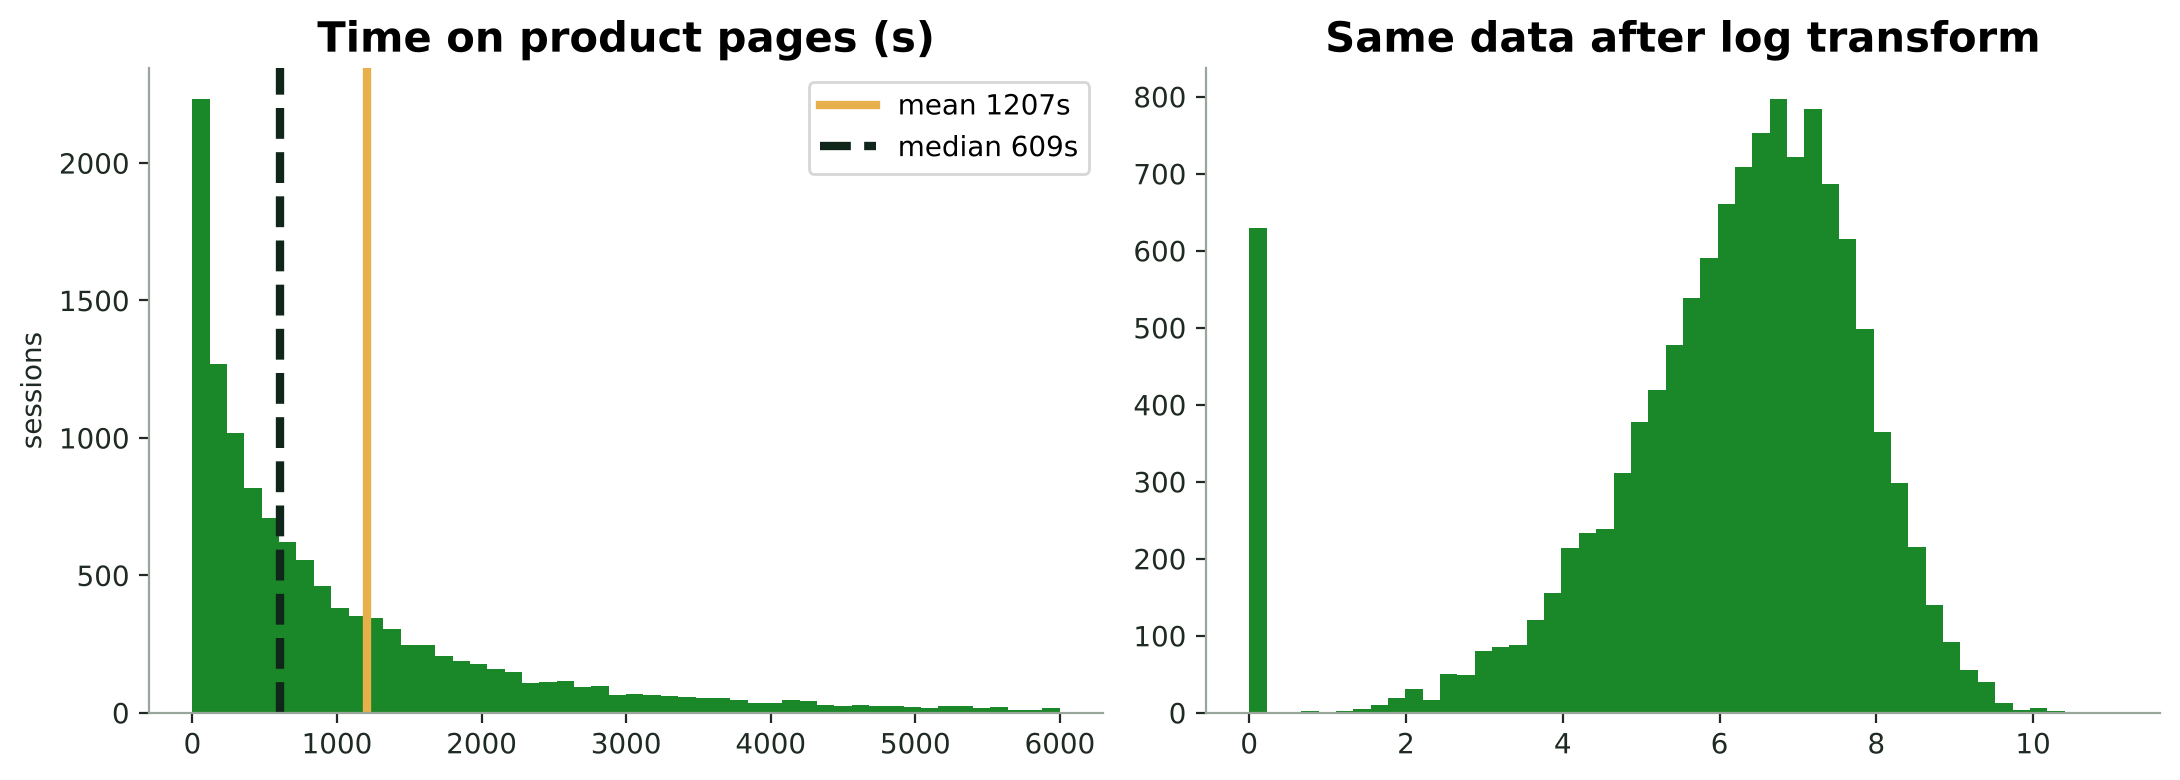

{'population_mean': np.float64(1207.0), 'simple_random': np.float64(1196.8), 'stratified': np.float64(1301.7), 'systematic': np.float64(1204.0)} {'mean_of_means': np.float64(1214.8), 'se_theory': np.float64(192.0), 'se_observed': np.float64(197.0)}
{'buyer_mean': np.float64(1876.2), 'nonbuyer_mean': np.float64(1083.0), 't': np.float64(14.2), 'p': 5.632073546936922e-44, 'mw_p': 4.183328282203313e-122} {'chi2': np.float64(130.7), 'p': 4.2255708283129954e-29, 'dof': 2, 'rates': {'New_Visitor': 24.93, 'Other': 19.75, 'Returning_Visitor': 14.09}} {'chi2': np.float64(9.2), 'p': 0.002413809785581609, 'rates': {0: 15.08, 1: 17.45}}


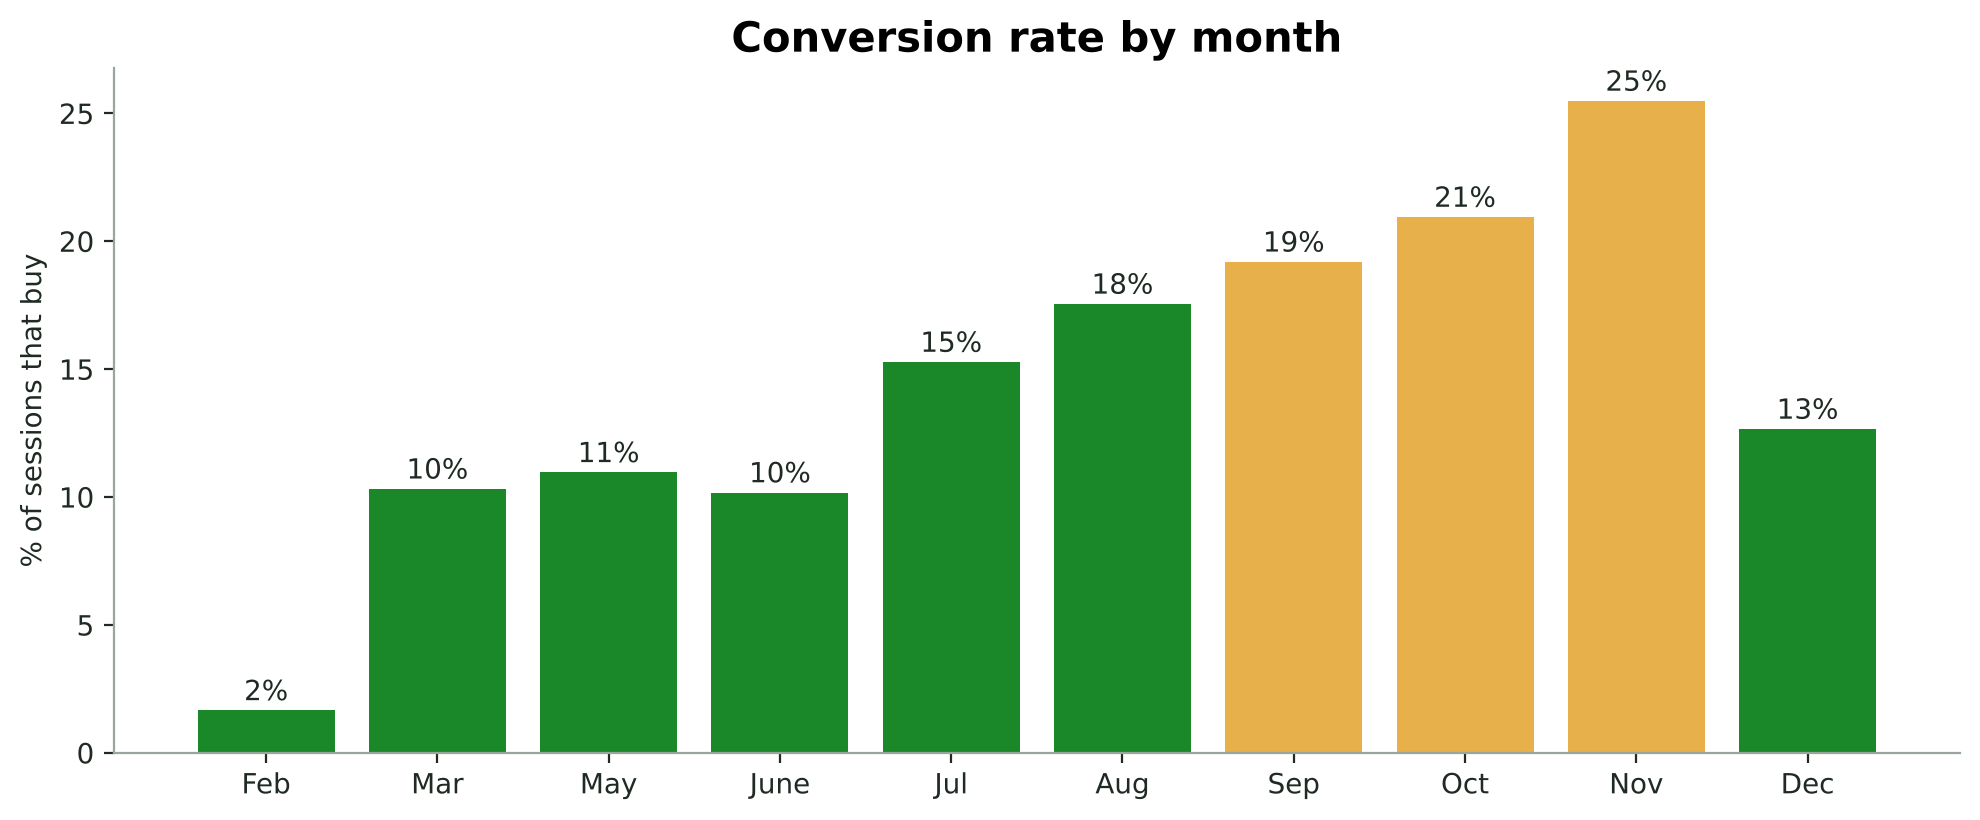

In [3]:
# ---------------- TASK 2: descriptive & inferential ----------------
key = ["Administrative","ProductRelated","ProductRelated_Duration","BounceRates","ExitRates","PageValues"]
desc = pd.DataFrame({"mean":df[key].mean(),"median":df[key].median(),"mode":df[key].mode().iloc[0],
                     "variance":df[key].var(),"std":df[key].std(),"skew":df[key].skew()})
R["desc"] = desc.round(3).to_dict("index"); print(desc.round(3))
fig,ax = plt.subplots(1,2,figsize=(11,4))
x = df["ProductRelated_Duration"]
ax[0].hist(x[x<6000],bins=50,color=GREEN); ax[0].axvline(x.mean(),color=AMBER,lw=3,label=f"mean {x.mean():.0f}s")
ax[0].axvline(x.median(),color=DARK,lw=3,ls="--",label=f"median {x.median():.0f}s"); ax[0].legend()
ax[0].set_title("Time on product pages (s)"); ax[0].set_ylabel("sessions")
ax[1].hist(np.log1p(x),bins=50,color=GREEN); ax[1].set_title("Same data after log transform")
save("dist")
# sampling techniques
pop_mean = df["ProductRelated_Duration"].mean()
srs = df.sample(500,random_state=1)
strat = df.groupby("Revenue",group_keys=False).apply(lambda g:g.sample(frac=500/len(df),random_state=1))
sys_s = df.iloc[::len(df)//500]
R["sampling"] = {"population_mean":round(pop_mean,1),"simple_random":round(srs.ProductRelated_Duration.mean(),1),
  "stratified":round(strat.ProductRelated_Duration.mean(),1),"systematic":round(sys_s.ProductRelated_Duration.mean(),1)}
means = [df.ProductRelated_Duration.sample(100).mean() for _ in range(2000)]
R["clt"] = {"mean_of_means":round(np.mean(means),1),"se_theory":round(df.ProductRelated_Duration.std()/10,1),"se_observed":round(np.std(means),1)}
print(R["sampling"],R["clt"])
# hypothesis tests
b = df[df.Revenue==1].ProductRelated_Duration; n_ = df[df.Revenue==0].ProductRelated_Duration
t,p = stats.ttest_ind(b,n_,equal_var=False)
u,pu = stats.mannwhitneyu(b,n_)
R["ttest"] = {"buyer_mean":round(b.mean(),1),"nonbuyer_mean":round(n_.mean(),1),"t":round(t,2),"p":float(p),"mw_p":float(pu)}
ct = pd.crosstab(df.VisitorType,df.Revenue); chi,pc,dof,_ = stats.chi2_contingency(ct)
vt = df.groupby("VisitorType").Revenue.mean()*100
R["chi_visitor"] = {"chi2":round(chi,1),"p":float(pc),"dof":int(dof),"rates":vt.round(2).to_dict()}
ct2 = pd.crosstab(df.Weekend,df.Revenue); chi2,pc2,_,_ = stats.chi2_contingency(ct2)
R["chi_weekend"] = {"chi2":round(chi2,1),"p":float(pc2),"rates":(df.groupby("Weekend").Revenue.mean()*100).round(2).to_dict()}
print(R["ttest"],R["chi_visitor"],R["chi_weekend"])
# conversion by month
order = ["Feb","Mar","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
mrate = (df.groupby("Month").Revenue.mean()*100).reindex(order)
R["month_rate"] = mrate.round(1).to_dict()
fig,ax = plt.subplots(figsize=(10,4.2))
ax.bar(mrate.index,mrate.values,color=[AMBER if v>=mrate.mean()+4 else GREEN for v in mrate.values])
for i,v in enumerate(mrate.values): ax.text(i,v+.4,f"{v:.0f}%",ha="center",fontsize=10,color=INK)
ax.set_title("Conversion rate by month"); ax.set_ylabel("% of sessions that buy"); save("month")

## TASK 3: probability

{'P_buy': np.float64(0.1563), 'P_hi': np.float64(0.32), 'P_buy_given_hi': np.float64(0.2289), 'P_buy_given_not_hi': np.float64(0.1222), 'P_pv': np.float64(0.2237), 'P_pv_given_buy': np.float64(0.8061), 'bayes': np.float64(0.5634), 'direct': np.float64(0.5634), 'P_buy_given_no_pv': np.float64(0.0391)}


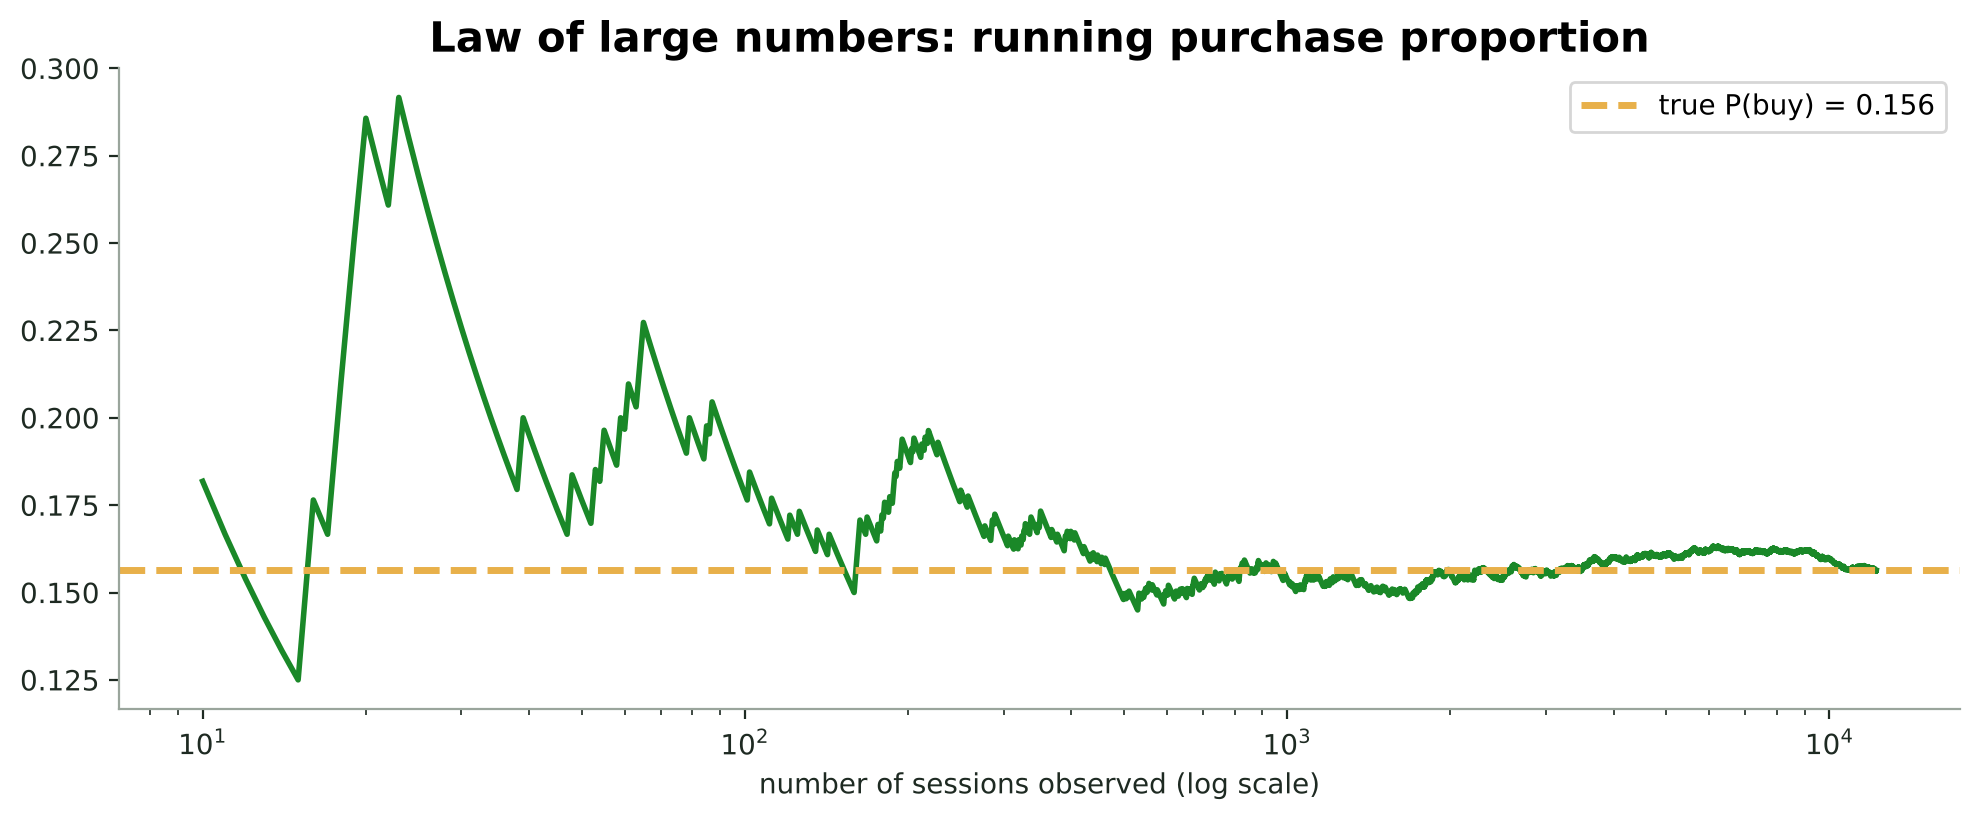

In [4]:
# ---------------- TASK 3: probability ----------------
P_buy = df.Revenue.mean()
pv = df.PageValues>0
P_pv = pv.mean(); P_buy_pv = df[pv].Revenue.mean()
hi = df.ProductRelated>30
P_buy_hi = df[hi].Revenue.mean()
P_pv_given_buy = pv[df.Revenue==1].mean()
bayes = P_pv_given_buy*P_buy/P_pv
R["prob"] = {"P_buy":round(P_buy,4),"P_hi":round(hi.mean(),4),"P_buy_given_hi":round(P_buy_hi,4),
  "P_buy_given_not_hi":round(df[~hi].Revenue.mean(),4),"P_pv":round(P_pv,4),"P_pv_given_buy":round(P_pv_given_buy,4),
  "bayes":round(bayes,4),"direct":round(P_buy_pv,4),"P_buy_given_no_pv":round(df[~pv].Revenue.mean(),4)}
print(R["prob"])
run = df.Revenue.sample(frac=1,random_state=3).reset_index(drop=True)
cum = run.expanding().mean()
fig,ax = plt.subplots(figsize=(10,4.2))
ax.plot(cum.index[10:],cum.values[10:],color=GREEN,lw=2); ax.axhline(P_buy,color=AMBER,lw=2.5,ls="--",label=f"true P(buy) = {P_buy:.3f}")
ax.set_xscale("log"); ax.set_title("Law of large numbers: running purchase proportion"); ax.set_xlabel("number of sessions observed (log scale)"); ax.legend()
save("lln")
R["lln"] = {str(n):round(float(cum[n-1]),3) for n in [10,100,1000,10000]}

## TASK 4: correlation

{'pearson': {'PageValues': 0.492, 'ProductRelated': 0.156, 'ProductRelated_Duration': 0.15, 'Administrative': 0.136, 'Informational': 0.094, 'Administrative_Duration': 0.092, 'Informational_Duration': 0.069, 'SpecialDay': -0.084, 'BounceRates': -0.145, 'ExitRates': -0.204}, 'spearman': {'PageValues': 0.626, 'ProductRelated_Duration': 0.213, 'ProductRelated': 0.194, 'Administrative': 0.164, 'Administrative_Duration': 0.161, 'Informational': 0.112, 'Informational_Duration': 0.11, 'SpecialDay': -0.088, 'BounceRates': -0.144, 'ExitRates': -0.251}}


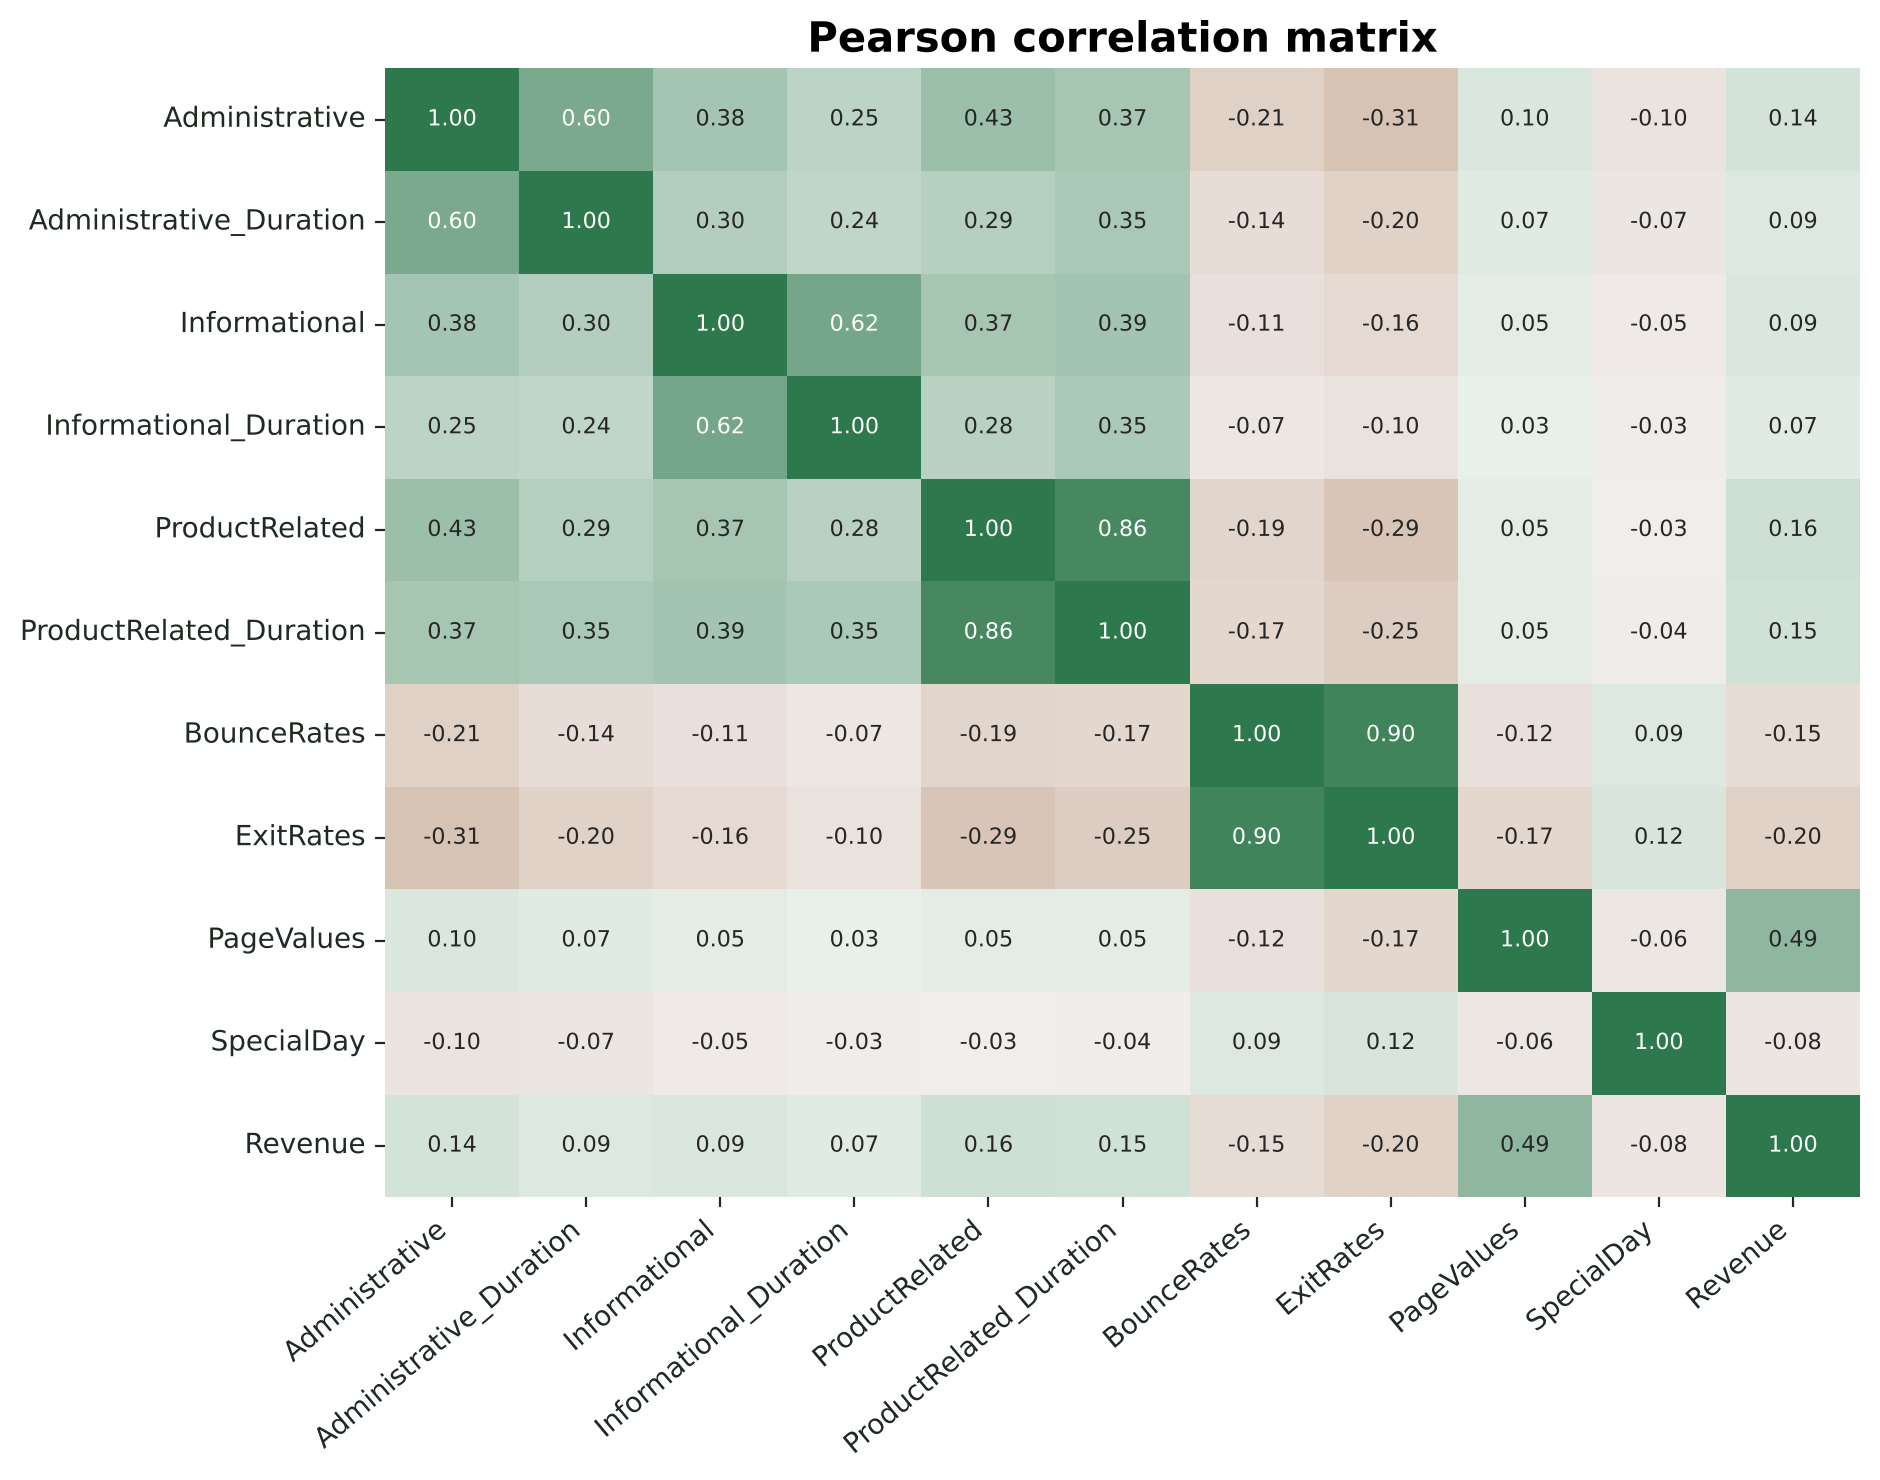

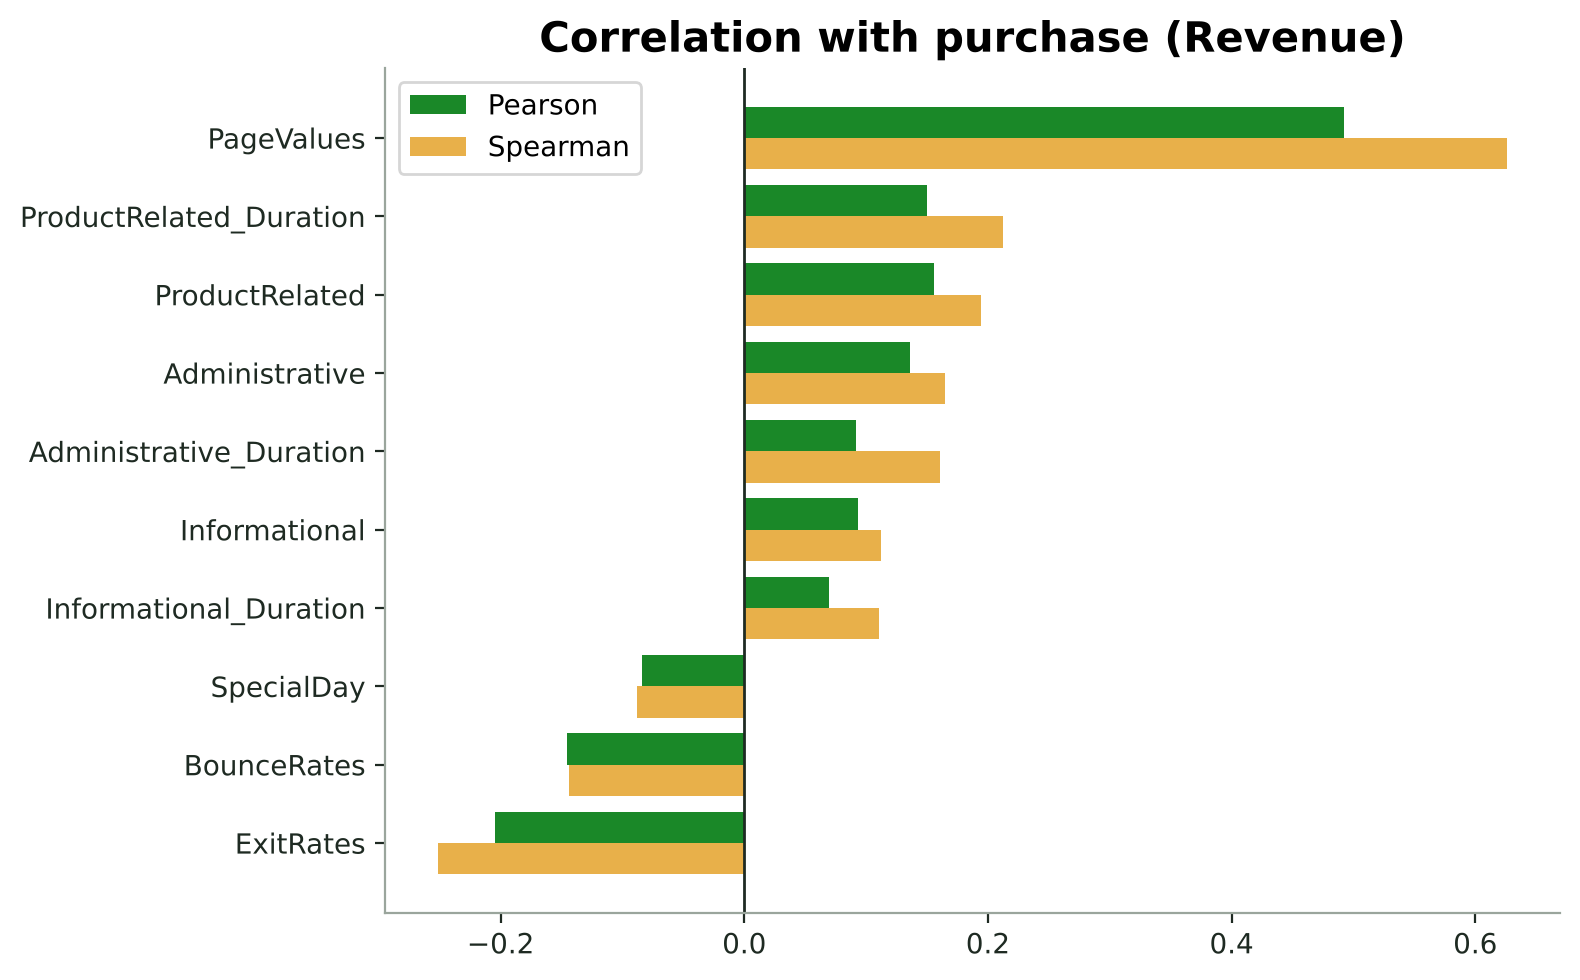

In [5]:
# ---------------- TASK 4: correlation ----------------
cn = ["Administrative","Administrative_Duration","Informational","Informational_Duration","ProductRelated",
      "ProductRelated_Duration","BounceRates","ExitRates","PageValues","SpecialDay","Revenue"]
pear = df[cn].corr("pearson"); spear = df[cn].corr("spearman")
R["corr_rev"] = {"pearson":pear.Revenue.drop("Revenue").round(3).sort_values(ascending=False).to_dict(),
                 "spearman":spear.Revenue.drop("Revenue").round(3).sort_values(ascending=False).to_dict()}
print(R["corr_rev"])
fig,ax = plt.subplots(figsize=(9.5,7.5))
sns.heatmap(pear,annot=True,fmt=".2f",cmap=sns.diverging_palette(35,140,s=80,l=45,as_cmap=True),center=0,ax=ax,cbar=False,annot_kws={"size":8})
ax.set_title("Pearson correlation matrix"); plt.xticks(rotation=40,ha="right"); save("corr")
r = pd.concat([pear.Revenue,spear.Revenue],axis=1,keys=["Pearson","Spearman"]).drop("Revenue").sort_values("Spearman")
fig,ax = plt.subplots(figsize=(8,5)); yy=np.arange(len(r)); ax.barh(yy+.2,r.Pearson,.4,color=GREEN,label="Pearson"); ax.barh(yy-.2,r.Spearman,.4,color=AMBER,label="Spearman")
ax.set_yticks(yy); ax.set_yticklabels(r.index); ax.axvline(0,color=INK,lw=1); ax.legend(); ax.set_title("Correlation with purchase (Revenue)"); save("corr_rev")

## TASK 5-8: regression (target: time on product pages)

SLR {'intercept': 6.82, 'slope': 37.61, 'MAE': 461.443, 'MSE': 634955.046, 'RMSE': 796.841, 'R2': 0.75}
MLR {'intercept': -66.17, 'coefs': {'Administrative': -61.18, 'Administrative_Duration': 1.75, 'Informational': 8.89, 'Informational_Duration': 1.48, 'ProductRelated': 36.26, 'BounceRates': -2455.26, 'ExitRates': 2527.5, 'PageValues': 0.66}, 'MAE': 459.203, 'MSE': 626650.27, 'RMSE': 791.612, 'R2': 0.753}


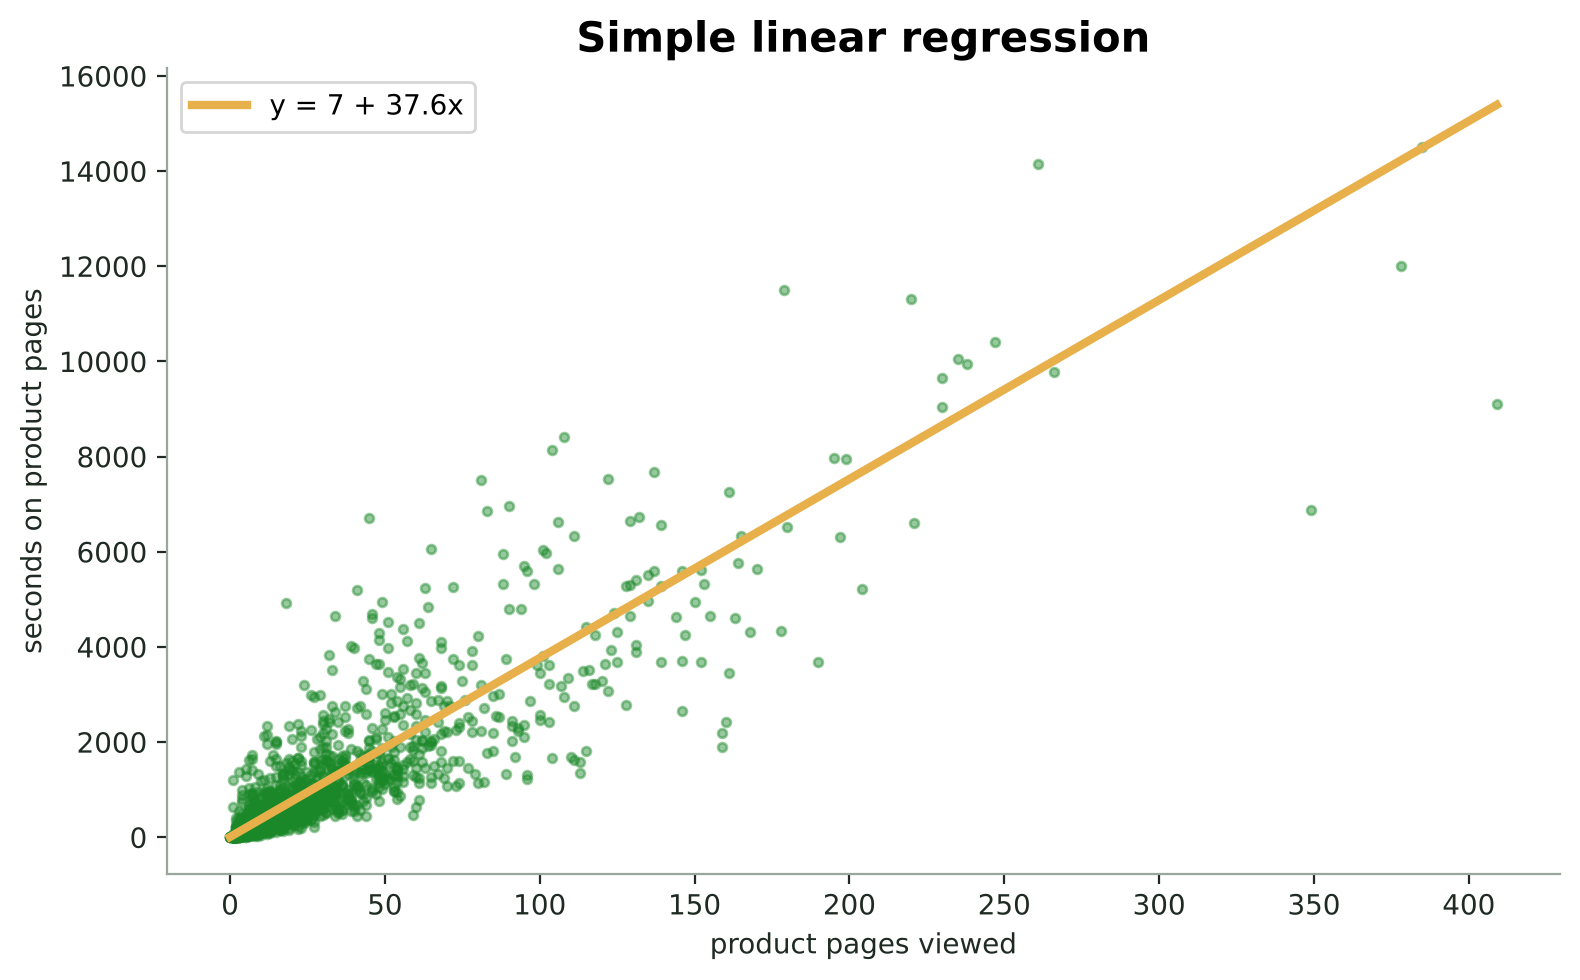

{'X_shape': [9764, 9], 'A+B_row0': [2.0, 0.0, 0.0, 0.0], 'dot_example': 1.0, 'beta_normal_eq': [-66.17, -61.18, 1.75, 8.89, 1.48, 36.26, -2455.26, 2527.5, 0.66], 'max_diff_vs_sklearn': 2.1373125491663814e-11, 'XtX_shape': [9, 9]}
{'lr': 0.1, 'iters': 100, 'cost_start': np.float64(2737916.2), 'cost_end': np.float64(519420.8), 'slope_gd': np.float64(37.61), 'intercept_gd': np.float64(6.82), 'slope_closed': 37.61, 'intercept_closed': 6.82, 'path': [(0.0, 0.0), (np.float64(171.1), np.float64(122.8)), (np.float64(325.2), np.float64(233.3)), (np.float64(463.8), np.float64(332.8)), (np.float64(588.6), np.float64(422.3))]}


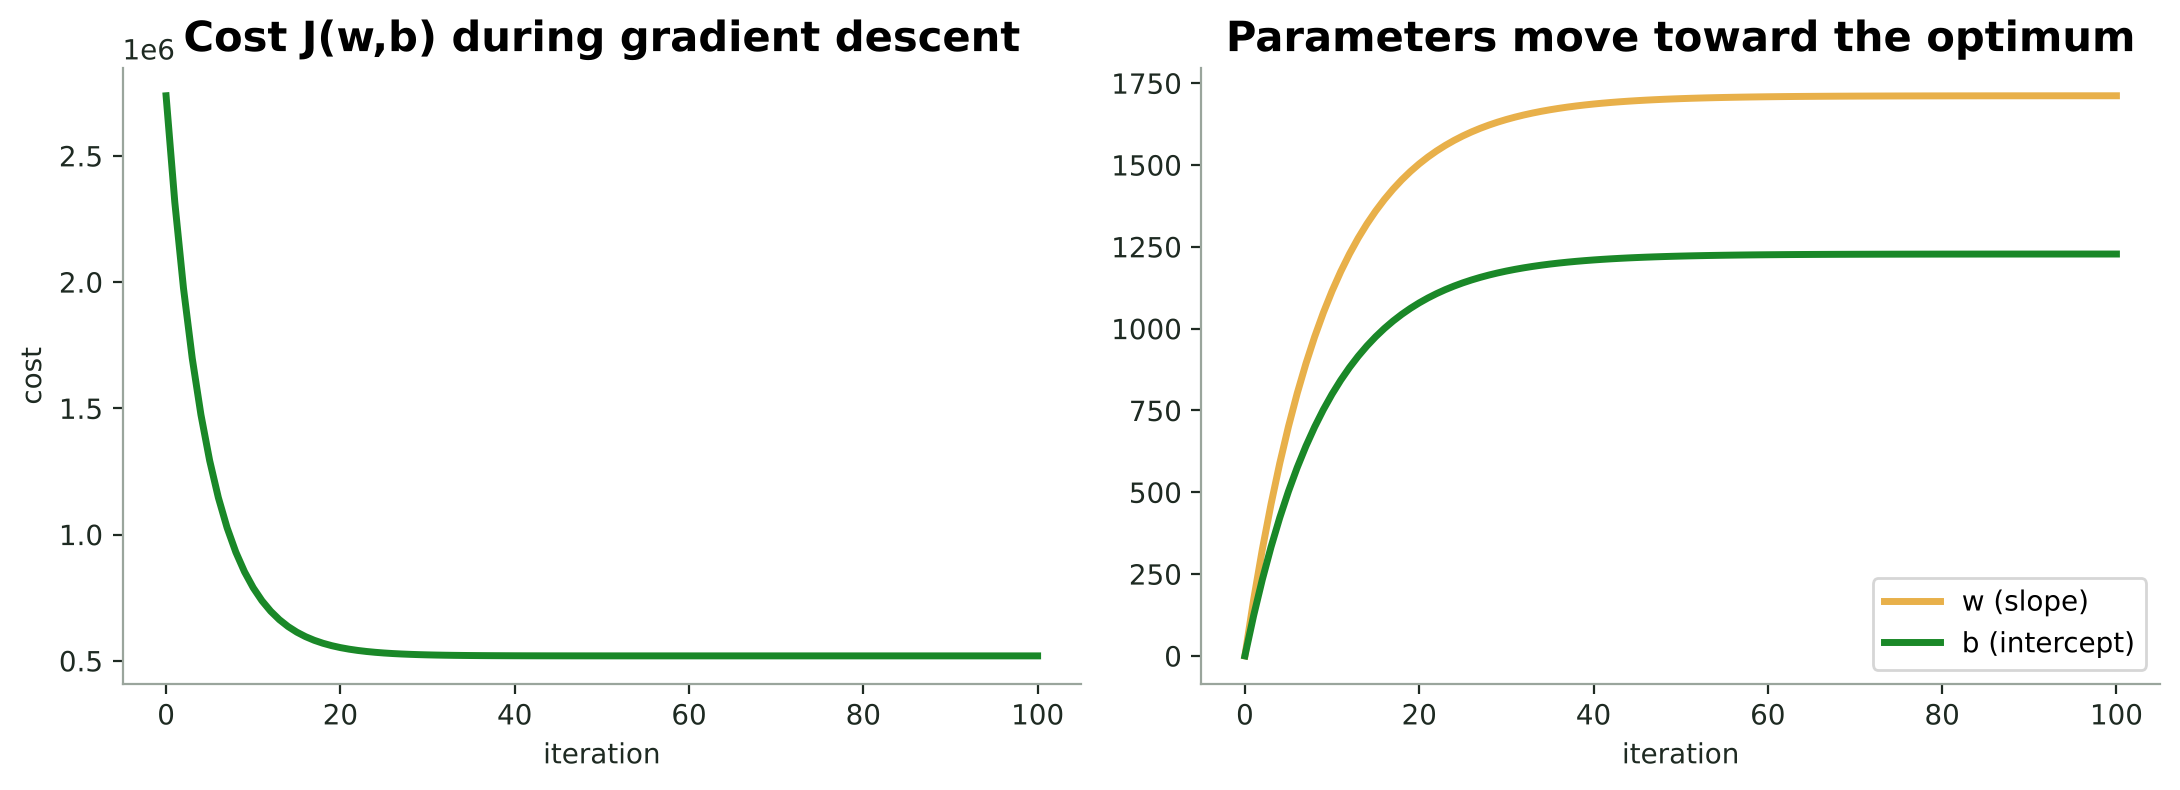

{'slr_mean': -25.91, 'mlr_mean': -18.31, 'mlr_under_pct': 40.3, 'under_high': 672.8, 'over_low': -127.8}


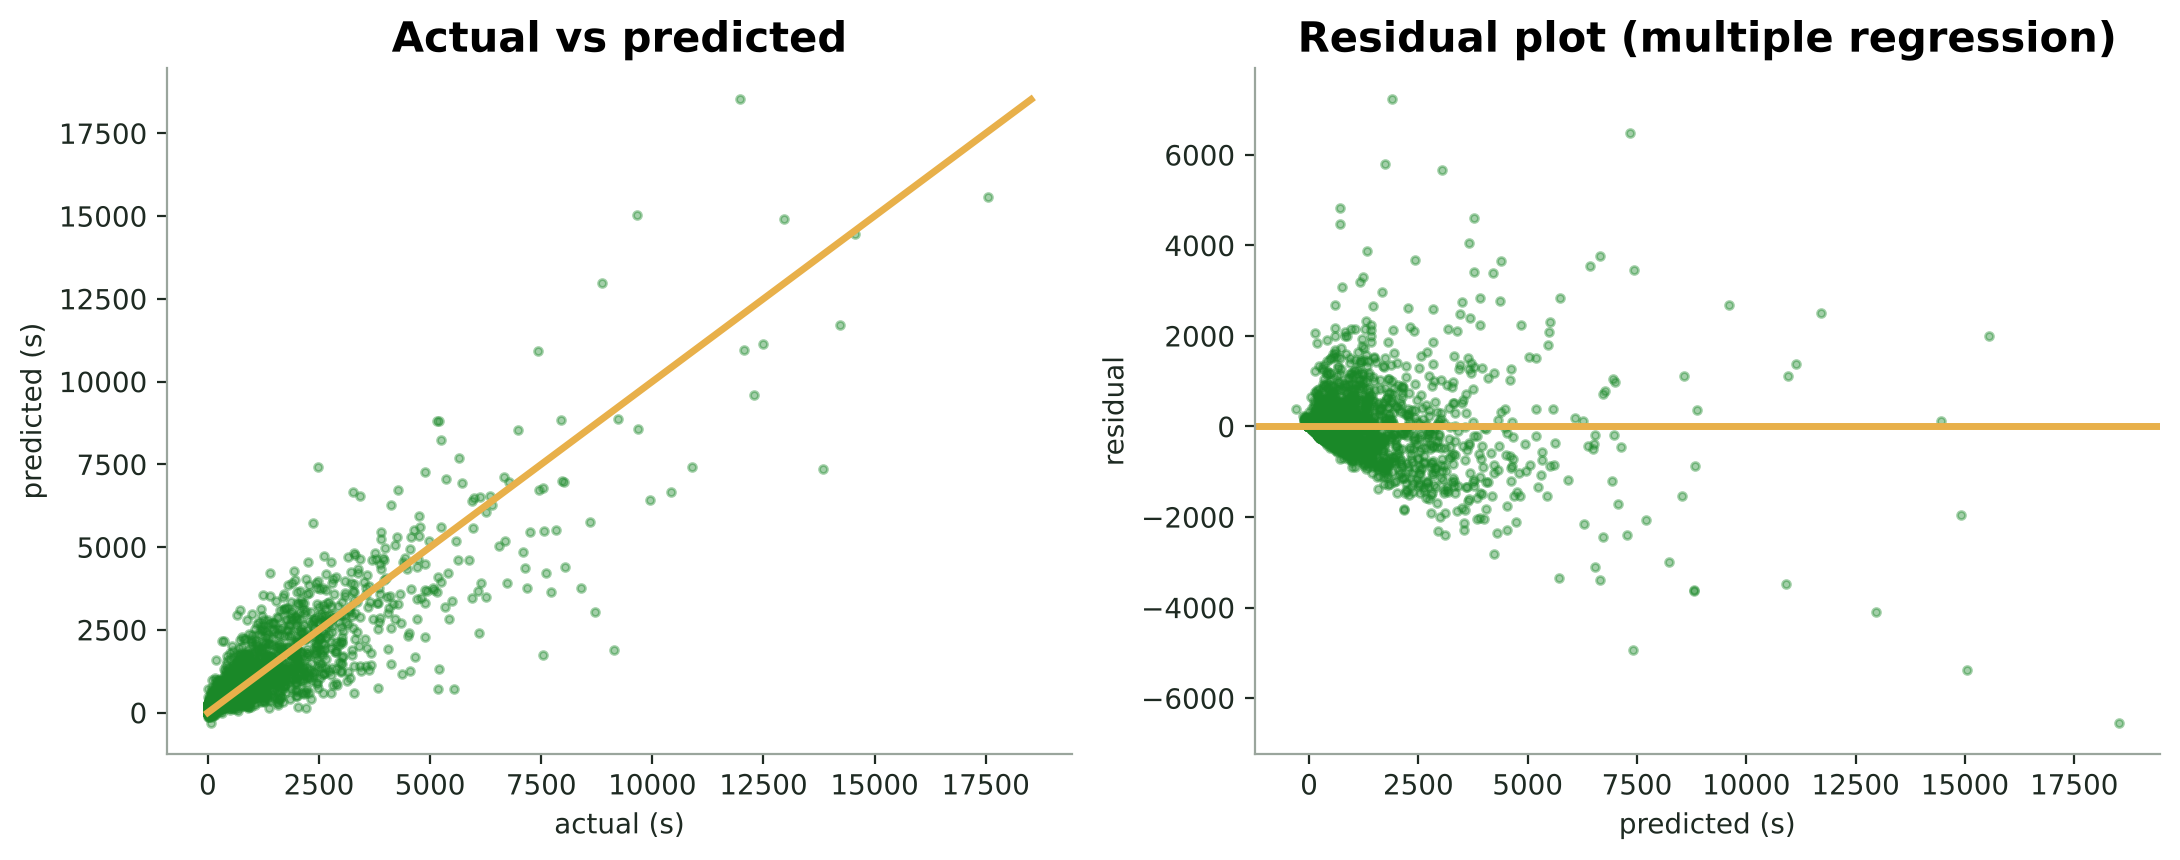

In [6]:
# ---------------- TASK 5-8: regression (target: time on product pages) ----------------
T = "ProductRelated_Duration"
feats = ["Administrative","Administrative_Duration","Informational","Informational_Duration","ProductRelated","BounceRates","ExitRates","PageValues"]
tr,te = train_test_split(df,test_size=0.2,random_state=11)
def metrics(y,p): return {"MAE":mean_absolute_error(y,p),"MSE":mean_squared_error(y,p),"RMSE":mean_squared_error(y,p)**.5,"R2":r2_score(y,p)}
slr = LinearRegression().fit(tr[["ProductRelated"]],tr[T]); mlr = LinearRegression().fit(tr[feats],tr[T])
p1 = slr.predict(te[["ProductRelated"]]); p2 = mlr.predict(te[feats]); y = te[T].values
R["pearson_slr"] = round(float(np.corrcoef(df.ProductRelated,df[T])[0,1]),3)
R["slr"] = {"intercept":round(float(slr.intercept_),2),"slope":round(float(slr.coef_[0]),2),**{k:round(v,3) for k,v in metrics(y,p1).items()}}
R["mlr"] = {"intercept":round(float(mlr.intercept_),2),"coefs":{f:round(float(c),2) for f,c in zip(feats,mlr.coef_)},**{k:round(v,3) for k,v in metrics(y,p2).items()}}
print("SLR",R["slr"]); print("MLR",R["mlr"])
fig,ax = plt.subplots(figsize=(8,5)); s=tr.sample(1500,random_state=2)
ax.scatter(s.ProductRelated,s[T],s=10,alpha=.45,color=GREEN); xs=np.linspace(0,s.ProductRelated.max(),50)
ax.plot(xs,slr.intercept_+slr.coef_[0]*xs,color=AMBER,lw=3,label=f"y = {slr.intercept_:.0f} + {slr.coef_[0]:.1f}x")
ax.set_xlabel("product pages viewed"); ax.set_ylabel("seconds on product pages"); ax.set_title("Simple linear regression"); ax.legend(); save("slr")

# ---- Task 6: linear algebra with NumPy
Xm = np.c_[np.ones(len(tr)),tr[feats].values]; yv = tr[T].values
A = Xm[:3,:4]; B = Xm[3:6,:4]
R["linalg"] = {"X_shape":list(Xm.shape),"A+B_row0":(A+B)[0].round(2).tolist(),"dot_example":round(float(A[0]@B[0]),2)}
XtX = Xm.T@Xm; Xty = Xm.T@yv
beta = np.linalg.solve(XtX,Xty)
R["linalg"]["beta_normal_eq"] = beta.round(2).tolist()
R["linalg"]["max_diff_vs_sklearn"] = float(np.abs(beta-np.r_[mlr.intercept_,mlr.coef_]).max())
R["linalg"]["XtX_shape"] = list(XtX.shape)
print(R["linalg"])

# ---- Task 7: gradient descent on the simple regression (standardised x)
x = tr.ProductRelated.values.astype(float); yy_ = yv.astype(float)
mx,sx = x.mean(),x.std(); xs_ = (x-mx)/sx
w,b0,lr = 0.0,0.0,0.1; hist=[]; path=[]
for i in range(101):
    pred = w*xs_+b0; err = pred-yy_
    cost = (err**2).mean()/2; hist.append(cost); path.append((w,b0))
    gw = (err*xs_).mean(); gb = err.mean()          # dJ/dw, dJ/db
    w -= lr*gw; b0 -= lr*gb
w_ = w/sx; b_ = b0-w*mx/sx
R["gd"] = {"lr":lr,"iters":100,"cost_start":round(hist[0],1),"cost_end":round(hist[-1],1),
           "slope_gd":round(w_,2),"intercept_gd":round(b_,2),"slope_closed":R["slr"]["slope"],"intercept_closed":R["slr"]["intercept"],
           "path":[(round(a,1),round(c,1)) for a,c in path[:5]]}
print(R["gd"])
fig,ax = plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(hist,color=GREEN,lw=2.5); ax[0].set_title("Cost J(w,b) during gradient descent"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("cost")
pp = np.array(path); ax[1].plot(pp[:,0],color=AMBER,lw=2.5,label="w (slope)"); ax[1].plot(pp[:,1],color=GREEN,lw=2.5,label="b (intercept)")
ax[1].set_title("Parameters move toward the optimum"); ax[1].set_xlabel("iteration"); ax[1].legend(); save("gd")

# ---- Task 8: evaluation & residuals
res2 = y-p2; res1 = y-p1
R["resid"] = {"slr_mean":round(float(res1.mean()),2),"mlr_mean":round(float(res2.mean()),2),
  "mlr_under_pct":round(float((res2>0).mean()*100),1),
  "under_high":round(float(res2[y>np.percentile(y,90)].mean()),1),"over_low":round(float(res2[y<np.percentile(y,25)].mean()),1)}
print(R["resid"])
fig,ax = plt.subplots(1,2,figsize=(11,4.4))
ax[0].scatter(y,p2,s=8,alpha=.4,color=GREEN); m=max(y.max(),p2.max()); ax[0].plot([0,m],[0,m],color=AMBER,lw=2.5)
ax[0].set_xlabel("actual (s)"); ax[0].set_ylabel("predicted (s)"); ax[0].set_title("Actual vs predicted")
ax[1].scatter(p2,res2,s=8,alpha=.4,color=GREEN); ax[1].axhline(0,color=AMBER,lw=2.5); ax[1].set_xlabel("predicted (s)"); ax[1].set_ylabel("residual"); ax[1].set_title("Residual plot (multiple regression)")
save("resid")

## Model development & optimisation (classification)

{'best': {'max_depth': 14, 'min_samples_leaf': 5, 'n_estimators': 200}, 'accuracy': 0.8673, 'auc': 0.9303, 'precision': 0.549, 'recall': 0.843, 'f1': 0.665, 'test_n': 2441} {'PageValues': 0.498, 'ExitRates': 0.089, 'ProductRelated_Duration': 0.073, 'ProductRelated': 0.058, 'BounceRates': 0.048, 'Month_Nov': 0.039, 'Administrative_Duration': 0.038, 'Administrative': 0.027}


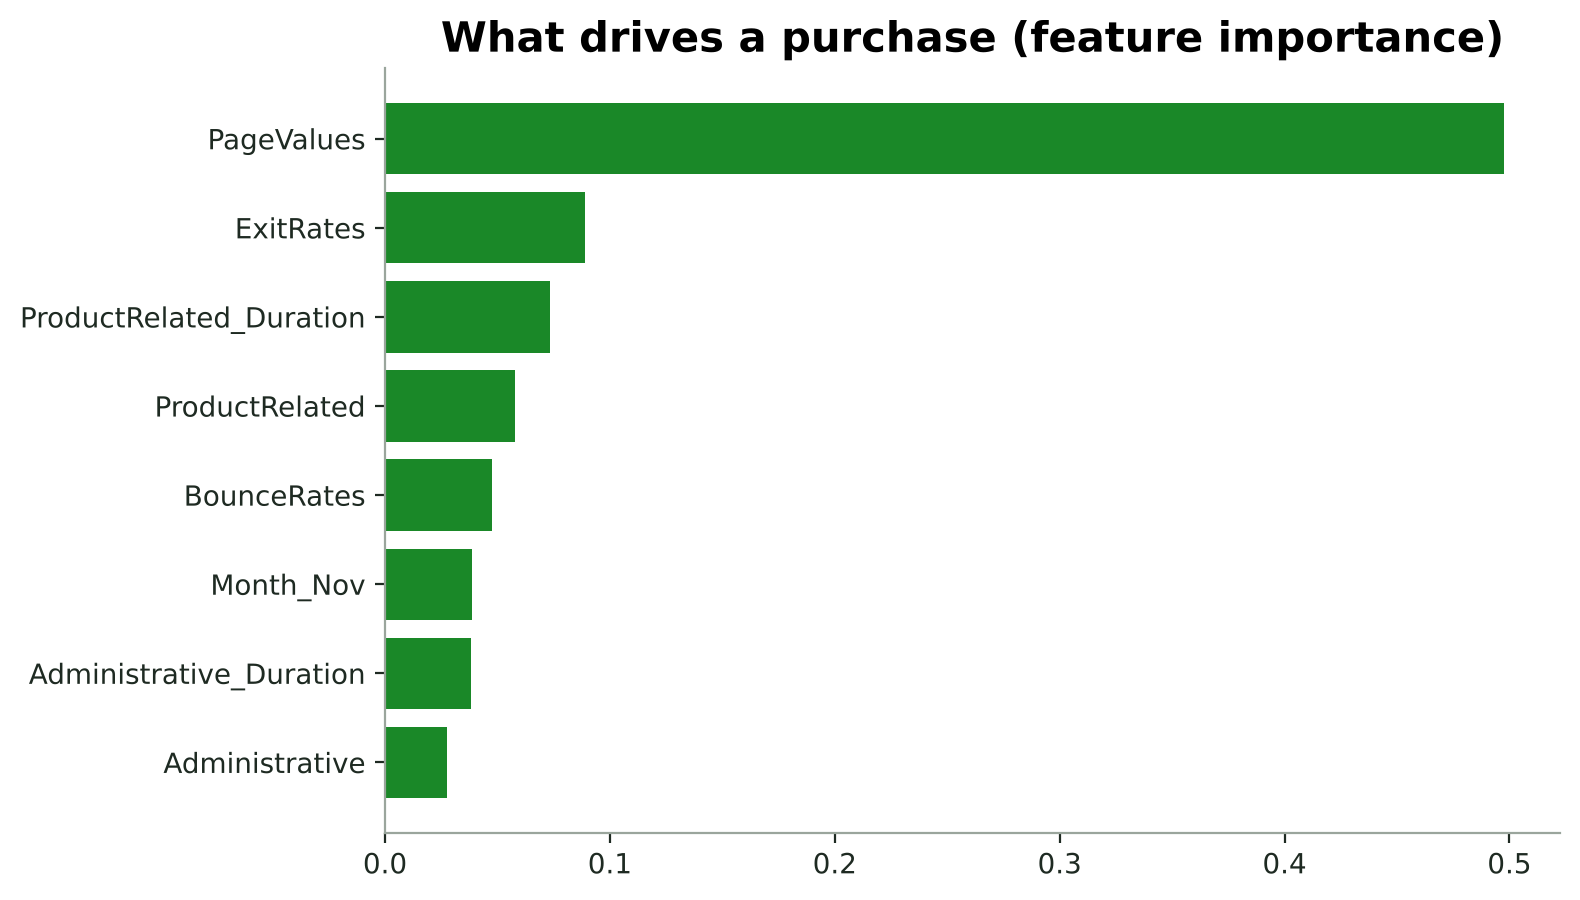

In [7]:
# ---------------- Model development & optimisation (classification) ----------------
Xc = pd.get_dummies(df.drop(columns="Revenue"),columns=["Month","VisitorType"],drop_first=True).astype(float); yc = df.Revenue
Xtr,Xte,ytr,yte = train_test_split(Xc,yc,test_size=.2,stratify=yc,random_state=11)
gs = GridSearchCV(RandomForestClassifier(class_weight="balanced",random_state=11,n_jobs=-1),
    {"n_estimators":[100,200],"max_depth":[8,14],"min_samples_leaf":[2,5]},scoring="roc_auc",cv=3).fit(Xtr,ytr)
pr = gs.predict(Xte); prb = gs.predict_proba(Xte)[:,1]
rep = classification_report(yte,pr,output_dict=True)
R["clf"] = {"best":gs.best_params_,"accuracy":round(accuracy_score(yte,pr),4),"auc":round(roc_auc_score(yte,prb),4),
  "precision":round(rep["1"]["precision"],3),"recall":round(rep["1"]["recall"],3),"f1":round(rep["1"]["f1-score"],3),"test_n":len(yte)}
imp = pd.Series(gs.best_estimator_.feature_importances_,index=Xc.columns).sort_values().tail(8)
R["clf_imp"] = imp.round(3).sort_values(ascending=False).to_dict()
print(R["clf"],R["clf_imp"])
fig,ax = plt.subplots(figsize=(8,4.6)); ax.barh(imp.index,imp.values,color=GREEN); ax.set_title("What drives a purchase (feature importance)"); save("imp")
pts=[10,20,50,100,200,500,1000,2000,5000,10000,len(cum)]
R["lln_curve"]={"n":pts,"p":[round(float(cum[n-1]),4) for n in pts]}
R["gd_cost"]=[round(float(h)) for h in hist[::5]]
R["gd_params_w"]=[round(float(a/sx),1) for a,_ in path[::10]]
sm=tr.sample(250,random_state=5); R["slr_pts"]=sm[["ProductRelated",T]].round(1).values.tolist()
rs=pd.DataFrame({"p":p2,"r":res2}).sample(250,random_state=5); R["resid_pts"]=rs.round(1).values.tolist()
_d=tr[["ProductRelated","Administrative","PageValues"]].head(4).values
_b=np.array([mlr.coef_[feats.index("ProductRelated")],mlr.coef_[feats.index("Administrative")],mlr.coef_[feats.index("PageValues")]])
R["demo"]={"A":_d[:2].round(1).tolist(),"B":_d[2:4].round(1).tolist(),"sum":(_d[:2]+_d[2:4]).round(1).tolist(),
 "beta":_b.round(2).tolist(),"dot":round(float(_d[0]@_b),1)}